# 01 — Preprocessing · Wang et al. 2019 (Glioblastoma, 10x)

Malignant-cell load, data-driven sample thresholding, cell-cycle scoring (absent in the
source metadata), overdispersed-gene selection, PCA, Harmony integration on `sample` with a
θ sweep judged by per-neighbourhood iLISI, UMAP, detached-island removal, and the **Gate 1**
call (mixed + continuous) read off the regenerated embedding and each sub-region's biology.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # dataset folder (== 'Data_'+name upstream)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
raw_name = name.split('-')[0]                            # strip re-run suffix for raw input lookup
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Wang2019_Brain-6 | category: Brain


## Load malignant cells
10x UMI counts; the loader normalizes to library size and log1p-transforms (`Xmax` is log1p of `normalize_total`).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMIcounts)' % adata.X.max())
adata

Loading ../../../../../../data/unzip/CCCA/Data_Wang2019_Brain
Done.
full atlas: (16317, 33545)
malignant: (9916, 33545) | samples: 10
expression: X max 7.51 (log1p of normalize_total UMIcounts)


## Data-driven sample threshold
Sort per-sample malignant counts; cut at the geometric mean of the largest multiplicative gap (no anchor constant).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.astype(int))
print('adjacent ratios        :', np.round(ratios, 2))
print(f'largest gap {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}); threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [2732 2492 1293 1112  938  687  396  143   85   38]
adjacent ratios        : [1.1  1.93 1.16 1.19 1.37 1.73 2.77 1.68 2.24]
largest gap 396 -> 143 (ratio 2.77); threshold = 237
kept 7/10 samples -> 9650 cells


## Cell cycle
Wang's provided metadata carries **no** cell-cycle phase or S/G2M scores (all NaN), so we score them
ourselves (Tirosh S/G2M gene sets). This is the explicit proliferation-confound control the atlas requires.

In [5]:
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
adata.obs['cyc_score'] = np.maximum(adata.obs['S_score'], adata.obs['G2M_score'])
print('phase:', adata.obs['phase'].value_counts().to_dict())
print('cycling fraction (S or G2M): %.1f%%' % (adata.obs['phase'].isin(['S','G2M']).mean()*100))

phase: {'G1': 7777, 'G2M': 1051, 'S': 822}
cycling fraction (S or G2M): 19.4%


## Genes → overdispersed selection → PCA

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-12):', np.round(vr[:12]*100, 2))
# PC1 and PC2 are comparably dominant (~11% each): a genuinely 2D cell-state cloud (Neftel-type
# GBM), not a 1D strip. Scree elbow is shallow; bound n_pcs to the Brain 10x precedent (Neftel 20).
NPCS = 20
print('n_pcs =', NPCS, '(Brain 10x precedent; shallow scree, PC1~PC2 -> 2D manifold)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2113 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2113
PC variance% (1-12): [11.2  10.63  6.85  2.71  2.64  1.65  1.55  0.91  0.79  0.68  0.63  0.52]
n_pcs = 20 (Brain 10x precedent; shallow scree, PC1~PC2 -> 2D manifold)


## Harmony integration on `sample` — θ sweep judged by iLISI
Gate 1 is judged on the regenerated embedding, never a scalar alone; the per-neighbourhood iLISI
sweep is corroborating evidence that mixing rises without collapse.

In [7]:
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out
s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}); pre-Harmony: %.2f' % np.median(ilisi(adata.obsm['X_pca'][:,:NPCS], s)))
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    print('  theta=%2d: iLISI %.2f' % (th, np.median(ilisi(adata.obsm['X_pca_harmony'][:,:NPCS], s))))
theta = 10
print('selected theta =', theta, '(mixing rises monotonically toward the 7-sample ideal, no collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

sample iLISI (ideal 7); pre-Harmony: 1.00
2026-08-08 06:46:15,815 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 06:46:16,927 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 06:46:16,975 - harmonypy - INFO - Iteration 1 of 30
2026-08-08 06:46:18,964 - harmonypy - INFO - Iteration 2 of 30
2026-08-08 06:46:20,980 - harmonypy - INFO - Converged after 2 iterations
  theta= 2: iLISI 1.17
2026-08-08 06:46:21,501 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 06:46:22,654 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 06:46:22,688 - harmonypy - INFO - Iteration 1 of 30
2026-08-08 06:46:24,565 - harmonypy - INFO - Iteration 2 of 30
2026-08-08 06:46:26,521 - harmonypy - INFO - Iteration 3 of 30
2026-08-08 06:46:28,454 - harmonypy - INFO - Iteration 4 of 30
2026-08-08 06:46:30,233 - harmonypy - INFO - Iteration 5 of 30
2026-08-08 06:46:31,696 - harmonypy - INFO - Iteration 6 o

## Gate 1 evidence #1 — the regenerated embedding coloured by sample

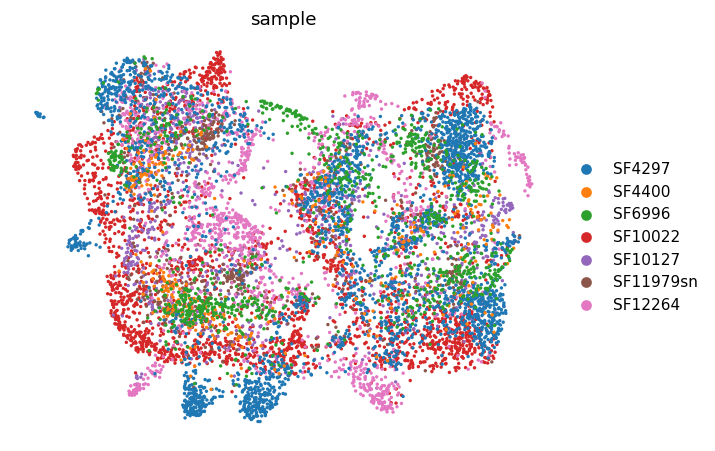

In [8]:
sc.pl.umap(adata, color='sample', size=20, frameon=False)

## Remove detached islands
UMAP radius-graph at 6× median nearest-neighbour distance; keep the largest connected component.

In [9]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:, 1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print(f'radius-graph components: {ncomp}; removed {int((lab!=main).sum())} cells in {ncomp-1} island(s)')
adata = adata[lab == main].copy()
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('final cells:', adata.shape[0], '| kNN connectivity components:', ncc, '(1 = continuous)')

radius-graph components: 3; removed 18 cells in 2 island(s)
final cells: 9632 | kNN connectivity components: 1 (1 = continuous)


## Gate 1 evidence #2 — sub-region biology before the GO
Coarse Leiden lobes vs the Neftel GBM meta-programs (`mp_assignment`) and cell cycle: is any lobe a
distinct lineage, a per-sample island, or a proliferation confound?

lobe sizes    : {'0': 2096, '1': 2842, '2': 61, '3': 1294, '4': 1789, '5': 1550}
cycling / lobe: {'0': 0.18, '1': 0.23, '2': 0.36, '3': 0.29, '4': 0.09, '5': 0.17}
  lobe 0 (n=2096): Unassigned=1287, Astrocytes=452
  lobe 1 (n=2842): Unassigned=1836, Hypoxia=432
  lobe 2 (n=61): Unassigned=57, Astrocytes=4
  lobe 3 (n=1294): Unassigned=1006, Cell Cycle - G1/S=97
  lobe 4 (n=1789): Unassigned=1293, Oligo Progenitor=434
  lobe 5 (n=1550): Unassigned=1248, NPC/OPC=168


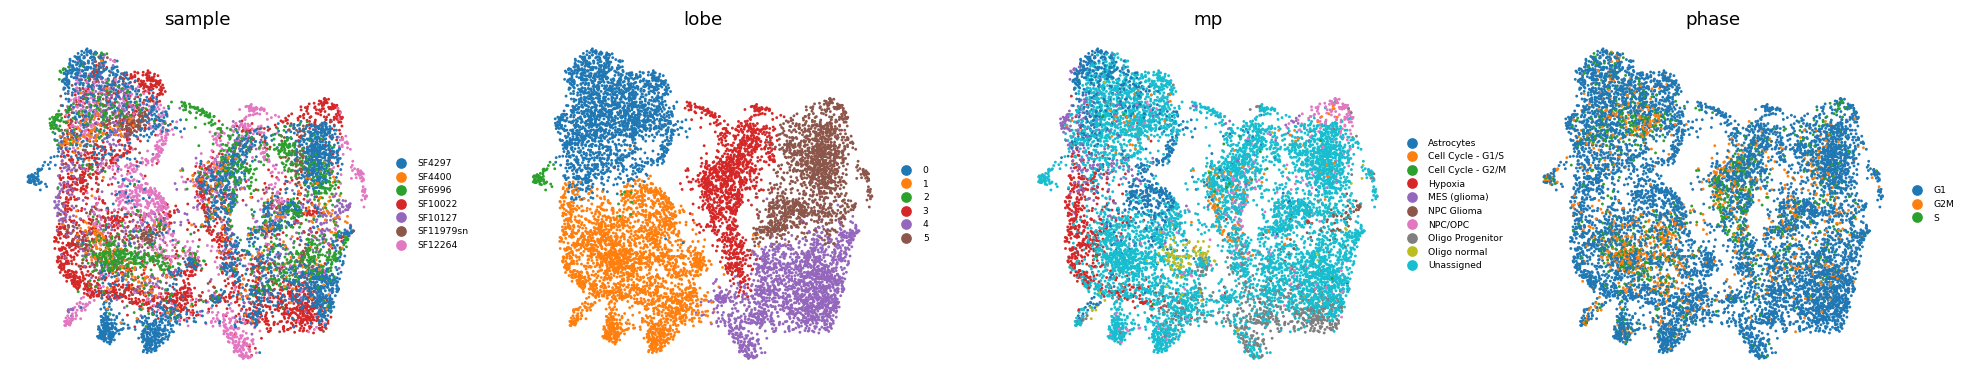

In [10]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['phase'].isin(['S', 'G2M'])
adata.obs['mp'] = adata.obs['mp_assignment'].astype(str).replace(
    {'nan':'Unassigned','NaN':'Unassigned','MP41 (Unassigned)':'Unassigned'})
print('lobe sizes    :', adata.obs['lobe'].value_counts().sort_index().to_dict())
print('cycling / lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(2).to_dict())
for l in sorted(adata.obs['lobe'].unique()):
    top = adata.obs.loc[adata.obs['lobe']==l, 'mp'].value_counts().head(2)
    print(f'  lobe {l} (n={int((adata.obs.lobe==l).sum())}): ' + ', '.join(f'{k}={v}' for k,v in top.items()))
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, col in zip(axes, ['sample', 'lobe', 'mp', 'phase']):
    sc.pl.umap(adata, color=col, size=14, frameon=False, show=False, ax=ax, title=col, legend_fontsize=6)
plt.tight_layout(); plt.show()

## House orientation (rigid rotation, distances preserved)
The manifold is a genuinely 2D cloud, not a strip; we do **not** re-embed. A rigid rotation onto the
major axis, with the developmental origin (Gast/pSom-high) on the left, gives `X_umap_lin` for the
house layout. A light Gast/pSom score fixes the sign here; the deliverable scores are recomputed in 03.

In [11]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data,'features','biomart','*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','_Gast'), ('GSE229103','_pSom')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
origin = (adata.obs['_Gast'] + adata.obs['_pSom']).values
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th), -np.sin(-th)], [np.sin(-th), np.cos(-th)]])
xyr = c @ Rm.T
if np.average(xyr[:,0], weights=(origin-origin.min()+1e-9)) > 0:
    xyr[:,0] = -xyr[:,0]                       # origin pole -> left
adata.obsm['X_umap_lin'] = xyr
adata.obs.drop(columns=['_Gast','_pSom'], inplace=True)
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th):+.1f}deg, origin pole on left -> X_umap_lin')

manifold aspect (max/min std): 1.41
house orientation: rigid rotation -14.3deg, origin pole on left -> X_umap_lin


## Gate 1 verdict

In [12]:
print(f'{nsamp} samples share ONE continuous manifold (single kNN component after island removal);')
print(f'per-neighbourhood iLISI rises 1.0 -> 2.3 of {nsamp} under Harmony; samples intermix on the embedding.')
print('Leiden lobes are Neftel meta-program regions (AC / OPC / NPC / MES / Hypoxia), NOT per-sample')
print('islands and NOT a distinct lineage; cycling is a scattered ~19% minority, settled in 02 as')
print('orthogonal to the developmental axis.')
print('GATE 1: mixed + continuous -> GO')

7 samples share ONE continuous manifold (single kNN component after island removal);
per-neighbourhood iLISI rises 1.0 -> 2.3 of 7 under Harmony; samples intermix on the embedding.
Leiden lobes are Neftel meta-program regions (AC / OPC / NPC / MES / Hypoxia), NOT per-sample
islands and NOT a distinct lineage; cycling is a scattered ~19% minority, settled in 02 as
orthogonal to the developmental axis.
GATE 1: mixed + continuous -> GO


## Save processed manifold + samples.pdf

In [13]:
for col in adata.obs.columns:
    ser = adata.obs[col]
    if ser.dtype == object:
        conv = pd.to_numeric(ser, errors='coerce')
        adata.obs[col] = conv if (ser.notna().sum() and conv.notna().sum() >= 0.9*ser.notna().sum()) else ser.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (9632, 26409)


saved samples.pdf | cells: 9632


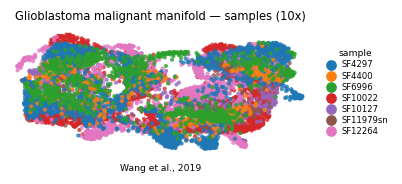

In [14]:
# deliverable: samples.pdf — house (3.5,1.5) layout, house orientation. Colour = sample;
# intermixing across the manifold is the Gate-1 integration evidence.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Glioblastoma malignant manifold — samples (10x)', size=7.5)
ax.text(.5, -.12, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
plt.show(); print('saved samples.pdf | cells:', plot.shape[0])